# Import si incarcare date

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("output/fact_agriculture_analytic.xlsx")
print("Dimensiune:", df.shape)
display(df.head())

Dimensiune: (48514, 17)


,FactID,time,temperature,humidity,pressure,pressure_vapor,radiation,precipitation,wind_speed,vane_direction,soil_time,temperature_depth_0,temperature_depth_1,temperature_depth_5,moisture_w-o_salinity_depth_5,time_difference_min,has_soil_data
0,1,2025-07-14 12:51:47,26.5,59.1,98.34,2.046,382.551,0.0,6.4,270,2025-07-14 12:50:31,30.06,30.07,21.74,33.74,1.266667,True
1,2,2025-07-14 12:56:46,26.8,57.1,98.33,2.009,366.046,0.0,3.2,225,2025-07-14 12:55:31,30.18,30.18,21.76,33.74,1.250000,True
2,3,2025-07-14 13:01:45,26.9,56.4,98.33,1.992,389.825,0.0,4.0,270,2025-07-14 13:00:28,30.17,30.14,21.76,33.73,1.283333,True
3,4,2025-07-14 13:06:45,26.8,56.1,98.33,1.975,377.796,0.0,11.2,270,2025-07-14 13:05:28,30.17,30.13,21.78,33.70,1.283333,True
4,5,2025-07-14 13:11:45,26.7,56.9,98.32,1.992,441.577,0.0,12.0,270,2025-07-14 13:10:31,29.99,29.99,21.77,33.67,1.233333,True


# Selectarea variabilelor

In [23]:
target = "temperature_depth_5"
features = [
    "temperature",
    "humidity",
    "pressure",
    "pressure_vapor",
    "radiation",
    "precipitation",
    "wind_speed",
    "vane_direction"
]
model_data = (
    df[df["has_soil_data"] == True]
    .sort_values(["soil_time", "time"])
    .drop_duplicates(subset=["soil_time"], keep="first")
    .dropna(subset=features + [target])
    .copy()
)
print("Randuri disponibile:", len(model_data))
display(model_data[features + [target]].head())

Randuri disponibile: 12705


,temperature,humidity,pressure,pressure_vapor,radiation,precipitation,wind_speed,vane_direction,temperature_depth_5
0,26.5,59.1,98.34,2.046,382.551,0.0,6.4,270,21.74
1,26.8,57.1,98.33,2.009,366.046,0.0,3.2,225,21.76
2,26.9,56.4,98.33,1.992,389.825,0.0,4.0,270,21.76
3,26.8,56.1,98.33,1.975,377.796,0.0,11.2,270,21.78
4,26.7,56.9,98.32,1.992,441.577,0.0,12.0,270,21.77


Am ales variabilele meteorologice pentru a estima temperatura solului ca sa il putem folosi si cand sonda de sol nu furnizeaza o citire.

# Train/Test Split 70/30

In [24]:
from sklearn.model_selection import train_test_split
import numpy as np
model_data = model_data.copy()
model_data["date"] = model_data["soil_time"].dt.normalize()
model_data["season"] = model_data["soil_time"].dt.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
})
model_data = model_data[
    model_data["season"].isin(["Spring", "Summer", "Autumn"])
].copy()
days = model_data[["date", "season"]].drop_duplicates()
train_days, test_days = train_test_split(
    days,
    test_size=0.30,
    random_state=42,
    stratify=days["season"]
)
train_data = model_data[
    model_data["date"].isin(train_days["date"])
].copy()
test_data = model_data[
    model_data["date"].isin(test_days["date"])
].copy()
X_train = train_data[features]
X_test = test_data[features]
y_train = train_data[target]
y_test = test_data[target]
print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("\nDistribuire pe anotimpuri:")
print(pd.crosstab(
    model_data["season"],
    np.where(model_data["date"].isin(train_days["date"]), "Train", "Test")
))

Train: (8885, 8)
Test: (3820, 8)

Distribuire pe anotimpuri:
col_0   Test  Train
season             
Autumn   957   2529
Spring   600   1326
Summer  2263   5030


# Linear Regression

In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

print("Linear Regression")
print(f"MAE: {mean_absolute_error(y_test, lr_pred):.3f} °C")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, lr_pred)):.3f} °C")
print(f"R2: {r2_score(y_test, lr_pred):.3f}")

Linear Regression
MAE: 1.466 °C
RMSE: 1.977 °C
R2: 0.902


# Random Forest

In [26]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest")
print(f"MAE: {mean_absolute_error(y_test, rf_pred):.3f} °C")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, rf_pred)):.3f} °C")
print(f"R2: {r2_score(y_test, rf_pred):.3f}")

Random Forest
MAE: 1.016 °C
RMSE: 1.505 °C
R2: 0.943


### Feature Importance pentru Random Forest

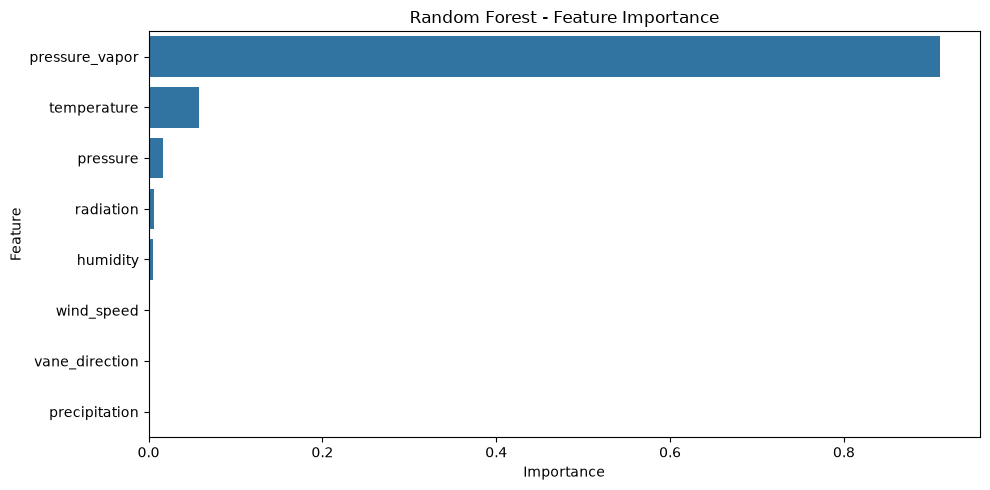

,importance
pressure_vapor,0.911
temperature,0.058
pressure,0.016
radiation,0.006
humidity,0.006
wind_speed,0.001
vane_direction,0.001
precipitation,0.000


In [27]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(
    x=importance.values,
    y=importance.index
)
plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
display(importance.to_frame("importance").round(3))

# XGBoost Regressor

In [29]:
from xgboost import XGBRegressor
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
print("XGBoost")
print(f"MAE: {mean_absolute_error(y_test, xgb_pred):.3f} °C")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, xgb_pred)):.3f} °C")
print(f"R2: {r2_score(y_test, xgb_pred):.3f}")

XGBoost
MAE: 0.994 °C
RMSE: 1.462 °C
R2: 0.946


## Compararea algoritmilor

In [30]:

results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": mean_absolute_error(y_test, lr_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, lr_pred)),
        "R2": r2_score(y_test, lr_pred)
    },
    {
        "Model": "Random Forest",
        "MAE": mean_absolute_error(y_test, rf_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, rf_pred)),
        "R2": r2_score(y_test, rf_pred)
    },
    {
        "Model": "XGBoost",
        "MAE": mean_absolute_error(y_test, xgb_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, xgb_pred)),
        "R2": r2_score(y_test, xgb_pred)
    }
])
display(results.round(3).sort_values("MAE"))


,Model,MAE,RMSE,R2
2,XGBoost,0.994,1.462,0.946
1,Random Forest,1.016,1.505,0.943
0,Linear Regression,1.466,1.977,0.902


## Grafic Actual vs Predicted

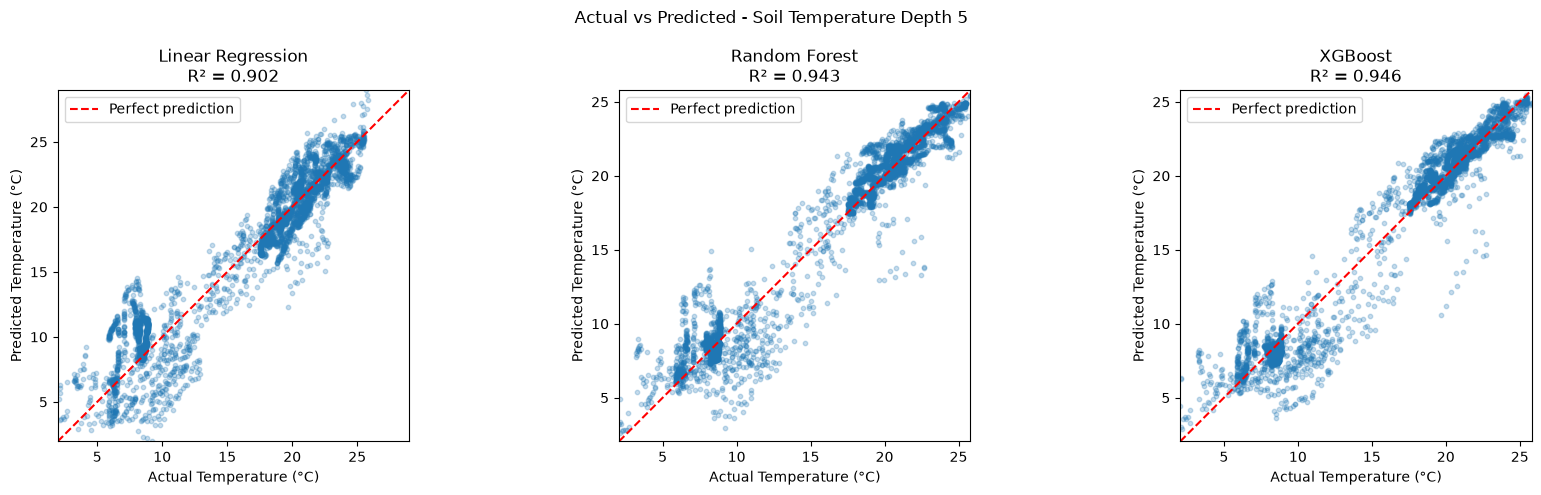

In [31]:
predictions = {
    "Linear Regression": lr_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred
}
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, alpha=0.25, s=10)
    limits = [
        min(y_test.min(), pred.min()),
        max(y_test.max(), pred.max())
    ]
    ax.plot(limits, limits, "r--", label="Perfect prediction")
    ax.set_title(f"{name}\nR² = {r2_score(y_test, pred):.3f}")
    ax.set_xlabel("Actual Temperature (°C)")
    ax.set_ylabel("Predicted Temperature (°C)")
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")
    ax.legend()
plt.suptitle("Actual vs Predicted - Soil Temperature Depth 5")
plt.tight_layout()
plt.show()

## Comparația performanțelor  Bar Chart

,Model,MAE,RMSE,R2
0,Linear Regression,1.466,1.977,0.902
1,Random Forest,1.016,1.505,0.943
2,XGBoost,0.994,1.462,0.946


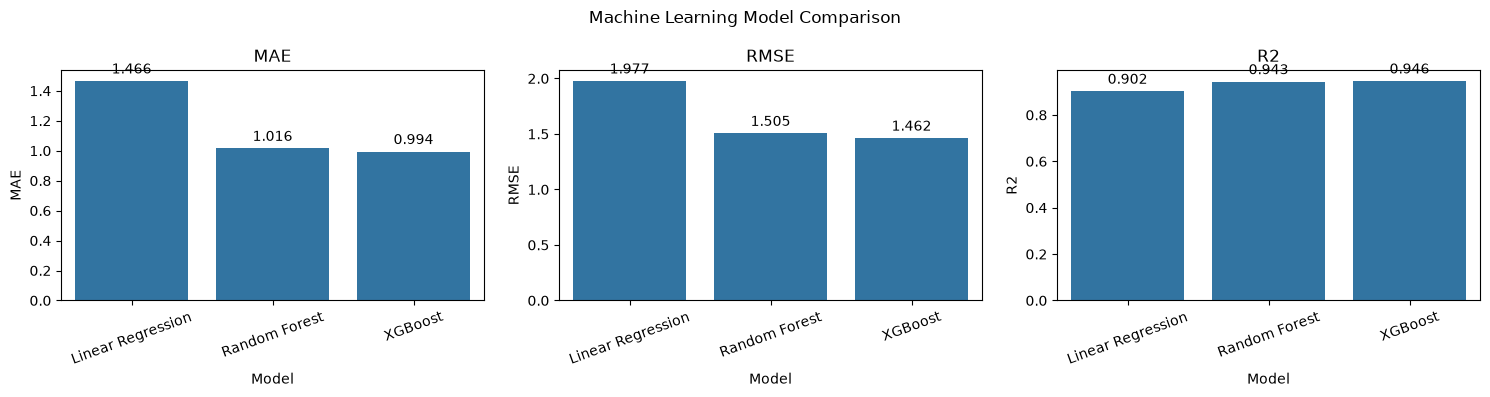

In [32]:
comparison = pd.DataFrame([
    {
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    }
    for name, pred in predictions.items()
])
display(comparison.round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    sns.barplot(data=comparison, x="Model", y=metric, ax=ax)
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=20)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3)
plt.suptitle("Machine Learning Model Comparison")
plt.tight_layout()
plt.show()

### Evolutia temp

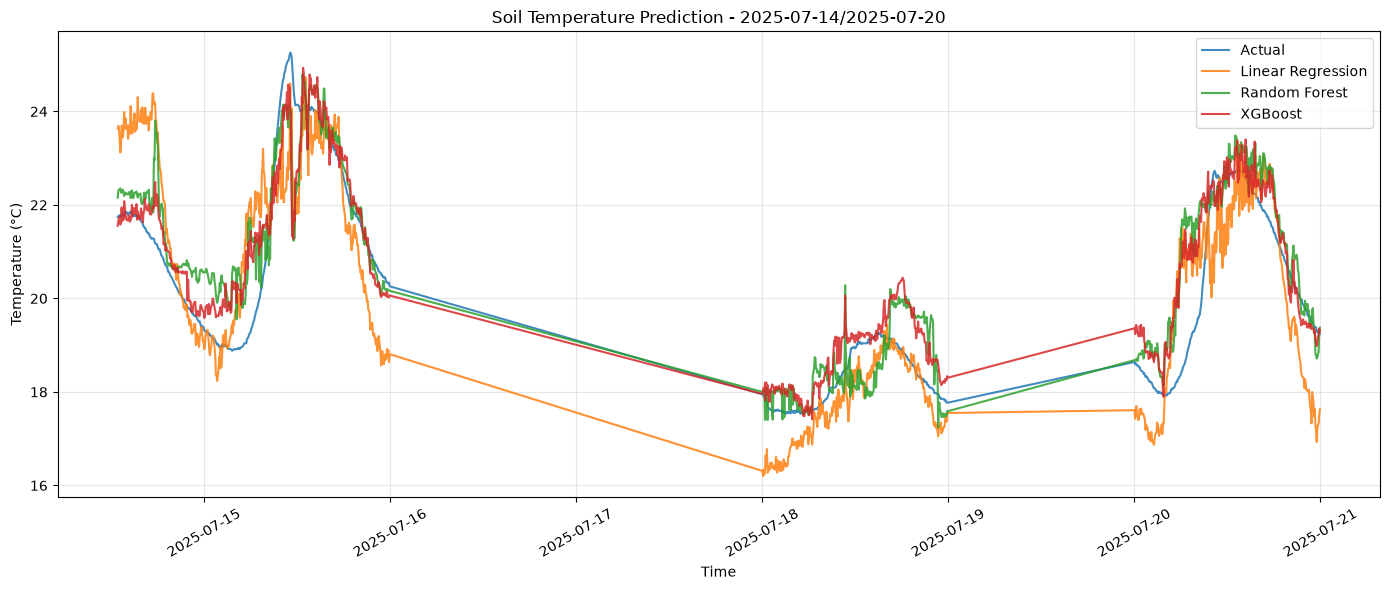

In [33]:
plot_data = test_data[["soil_time"]].copy()
plot_data["Actual"] = y_test.to_numpy()
for name, pred in predictions.items():
    plot_data[name] = pred
plot_data = plot_data.sort_values("soil_time")
weekly_counts = (
    plot_data.groupby(
        plot_data["soil_time"].dt.to_period("W")
    ).size()
)
best_week = weekly_counts.idxmax()
weekly_data = plot_data[
    plot_data["soil_time"].dt.to_period("W") == best_week
].copy()
plt.figure(figsize=(14, 6))
for col in ["Actual"] + list(predictions):
    plt.plot(
        weekly_data["soil_time"],
        weekly_data[col],
        label=col,
        linewidth=1.5,
        alpha=0.85
    )
plt.title(f"Soil Temperature Prediction - {best_week}")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()